# 03 · Features

Day 3 check: what does the feature table look like, and do the features carry signal?

1. The feature table: size and feature groups
2. Missing values per feature
3. Top correlations with log revenue and with score (train only)
4. Themes: size, typical results and examples
5. Track record: new vs experienced people
6. Synopsis embeddings: a 2-D view by genre

Reads the `features` table in `data/movies.db` (build it with `make features`) and `ml/features/feature_list.json`.
**The test split stays locked:** its features are counted, but its revenues and scores are never used here.

In [1]:
import json
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = sqlite3.connect(f"file:{(ROOT / 'data' / 'movies.db').as_posix()}?mode=ro", uri=True)
feature_info = pd.DataFrame(json.loads((ROOT / "ml" / "features" / "feature_list.json").read_text(encoding="utf-8")))


def sql(query, **params):
    return pd.read_sql_query(query, con, params=params)


features = sql("SELECT * FROM features")
names = feature_info["name"].tolist()
meta = json.loads(con.execute("SELECT value FROM meta WHERE key = 'features'").fetchone()[0])
print("built:", meta["built_at"], "| films:", f"{meta['films']:,}", "| features:", meta["features"])
assert names == [c for c in features.columns if c not in ("movie_id", "split")]

built: 2026-10-21T12:45:01+00:00 | films: 79,199 | features: 169


## 1. The feature table

In [2]:
groups = feature_info.groupby("source").agg(features=("name", "size"), example=("name", "first"))
print(features["split"].value_counts().to_dict())
groups.sort_values("features", ascending=False)

{'train': 67199, 'test': 8400, 'validation': 3600}


,features,example
source,,
companies,33,company_universal_pictures
themes,27,theme_based_on_a_book
track record (earlier films only),24,director_n_films
genres,19,genre_action
countries,17,country_US
synopsis (MiniLM + PCA),17,synopsis_00
language,16,language_en
certification,6,cert_g
release date,5,year


In [3]:
print("Features each model may use:", {m: int(feature_info["models"].map(lambda ms: m in ms).sum()) for m in ("revenue", "budget", "score")})
print("Kept out of a model:", {r["name"]: sorted({"revenue", "budget", "score"} - set(r["models"])) for _, r in feature_info.iterrows()
                               if len(r["models"]) < 3})

Features each model may use: {'revenue': 169, 'budget': 168, 'score': 169}
Kept out of a model: {'log_budget': ['budget']}


## 2. Missing values

Only numeric features can be missing (yes/no columns are always 0 or 1). LightGBM handles missing values itself.

In [4]:
missing = features[names].isna().groupby(features["split"]).mean().T[["train", "validation", "test"]]
missing = missing[missing.max(axis=1) > 0].mul(100).round(1)
missing.columns = [f"{c}_%" for c in missing.columns]
missing

,train_%,validation_%,test_%
runtime,1.8,0.1,0.5
franchise_revenue,97.8,94.6,95.5
log_budget,83.1,67.7,76.6
director_revenue,0.9,0.0,0.0
director_score,1.0,0.0,0.0
actors_revenue_max,0.9,0.0,0.0
actors_revenue_mean,0.9,0.0,0.0
actors_revenue_min,0.9,0.0,0.0
actors_score_max,1.0,0.0,0.0
actors_score_mean,1.0,0.0,0.0


In [5]:
f = features.set_index("movie_id")
print(f"films with any theme: {100 * (f.filter(like='theme_').sum(axis=1) > 0).mean():.1f}%")
print(f"films with a synopsis: {100 * f['has_synopsis'].mean():.1f}%")
print(f"films with no company: {100 * f['company_unknown'].mean():.1f}% | no country: {100 * f['country_unknown'].mean():.1f}%")
print(f"unrated/unknown certification: {100 * f['cert_unrated_unknown'].mean():.1f}%")

films with any theme: 48.3%
films with a synopsis: 98.9%
films with no company: 10.1% | no country: 2.8%
unrated/unknown certification: 70.5%


## 3. Top correlations (train only)

Spearman correlation between each feature and the target, on train films in that model's view:
log revenue (2025 dollars) for `v_train_revenue`, `vote_average` for `v_train_score`. These are single-feature
signals only; the models on Day 5 combine them.

In [6]:
revenue = sql("SELECT id AS movie_id, LN(revenue_2025) AS target FROM v_train_revenue WHERE split = 'train'")
score = sql("SELECT id AS movie_id, vote_average AS target FROM v_train_score WHERE split = 'train'")


def top_correlations(target, model, n=15):
    allowed = feature_info.loc[feature_info["models"].map(lambda ms: model in ms), "name"]
    d = target.merge(features, on="movie_id")
    corr = d[allowed].corrwith(d["target"], method="spearman").dropna()
    out = corr.reindex(corr.abs().sort_values(ascending=False).index).head(n).round(3).rename("spearman").to_frame()
    out["source"] = feature_info.set_index("name").loc[out.index, "source"]
    return out, len(d)


rev_corr, n_rev = top_correlations(revenue, "revenue")
print(f"log revenue, {n_rev:,} train films")
rev_corr

log revenue, 8,050 train films


C:\Users\dimbl\Desktop\Movies_Final_project\.venv\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,spearman,source
franchise_revenue,0.813,franchise (earlier films in the collection)
log_budget,0.675,budget (2025 dollars)
major_studio,0.407,companies
actors_revenue_max,0.400,track record (earlier films only)
actors_revenue_mean,0.389,track record (earlier films only)
director_revenue,0.374,track record (earlier films only)
cert_unrated_unknown,-0.324,certification
country_US,0.306,countries
language_en,0.254,language
runtime,0.244,runtime


In [7]:
score_corr, n_score = top_correlations(score, "score")
print(f"score, {n_score:,} train films")
score_corr

score, 22,016 train films


C:\Users\dimbl\Desktop\Movies_Final_project\.venv\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,spearman,source
actors_score_mean,0.413,track record (earlier films only)
actors_score_min,0.403,track record (earlier films only)
director_score,0.383,track record (earlier films only)
actors_score_max,0.331,track record (earlier films only)
genre_horror,-0.300,genres
runtime,0.245,runtime
genre_drama,0.240,genres
language_en,-0.222,language
franchise_revenue,0.217,franchise (earlier films in the collection)
genre_animation,0.183,genres


## 4. Themes (train)

In [8]:
theme_cols = [c for c in names if c.startswith("theme_")]
tr = features[features["split"] == "train"].set_index("movie_id")
rev_t = revenue.set_index("movie_id")["target"]
score_t = score.set_index("movie_id")["target"]
rows = []
for c in theme_cols:
    on = tr.index[tr[c] == 1]
    rows.append({
        "theme": c.removeprefix("theme_"),
        "train_films": len(on),
        "pct": round(100 * len(on) / len(tr), 1),
        "median_revenue_m": round(np.exp(rev_t.reindex(on).dropna().median()) / 1e6, 1),
        "revenue_films": int(rev_t.reindex(on).notna().sum()),
        "mean_score": round(score_t.reindex(on).dropna().mean(), 2),
    })
themes = pd.DataFrame(rows).sort_values("median_revenue_m", ascending=False)
print(f"all train revenue films: median ${np.exp(rev_t.median()) / 1e6:.1f}M | all train score films: mean {score_t.mean():.2f}")
themes

all train revenue films: median $36.8M | all train score films: mean 6.30


,theme,train_films,pct,median_revenue_m,revenue_films,mean_score
12,superhero,614,0.9,258.7,316,6.47
2,sequel_or_remake,1719,2.6,116.9,753,5.98
6,spy_and_conspiracy,1210,1.8,88.0,438,6.32
13,fantasy_and_magic,731,1.1,87.6,253,6.44
11,science_fiction,1963,2.9,86.5,596,6.17
0,based_on_a_book,4598,6.8,77.3,1338,6.60
14,survival_and_adventure,1954,2.9,72.1,634,6.26
25,christmas_and_holidays,747,1.1,71.2,117,6.20
7,action_and_martial_arts,2476,3.7,67.9,707,6.35
22,comedy_and_satire,1647,2.5,59.3,496,6.25


In [9]:
# Examples: the three most-voted train films per theme (vote_count is used for display only, never as a feature).
votes = sql("SELECT id AS movie_id, title, year, vote_count FROM movies WHERE split = 'train'").set_index("movie_id")
examples = {c.removeprefix("theme_"): ", ".join(f"{t} ({y})" for t, y in
            votes.loc[tr.index[tr[c] == 1]].nlargest(3, "vote_count")[["title", "year"]].itertuples(index=False))
            for c in theme_cols}
pd.Series(examples, name="most-voted examples").to_frame()

,most-voted examples
based_on_a_book,"The Avengers (2012), The Dark Knight (2008), F..."
true_story,"Titanic (1997), The Wolf of Wall Street (2013)..."
sequel_or_remake,The Lord of the Rings: The Return of the King ...
crime_and_police,"The Dark Knight (2008), The Shawshank Redempti..."
heist,"Inception (2010), Ant-Man (2015), Now You See ..."
murder_and_revenge,"Inception (2010), The Dark Knight (2008), Iron..."
spy_and_conspiracy,"Inception (2010), The Dark Knight Rises (2012)..."
action_and_martial_arts,"Fight Club (1999), The Matrix (1999), The Dark..."
history_and_war,"The Shawshank Redemption (1994), Forrest Gump ..."
supernatural,Harry Potter and the Philosopher's Stone (2001...


## 5. Track record: new vs experienced (train)

In [10]:
d = revenue.merge(features, on="movie_id")
d["director"] = pd.cut(d["director_n_films"], [-1, 0, 2, 5, 10, 1000], labels=["new", "1-2", "3-5", "6-10", "11+"])
by_director = d.groupby("director", observed=True).agg(films=("target", "size"), median_revenue_m=("target", "median"))
by_director["median_revenue_m"] = (np.exp(by_director["median_revenue_m"]) / 1e6).round(1)
s = score.merge(features, on="movie_id")
s["director"] = pd.cut(s["director_n_films"], [-1, 0, 2, 5, 10, 1000], labels=["new", "1-2", "3-5", "6-10", "11+"])
by_director["score_films"] = s.groupby("director", observed=True).size()
by_director["mean_score"] = s.groupby("director", observed=True)["target"].mean().round(2)
print("Revenue and score by the director's number of earlier films:")
by_director

Revenue and score by the director's number of earlier films:


,films,median_revenue_m,score_films,mean_score
director,,,,
new,1629,13.7,5608,6.19
1-2,2052,34.5,5575,6.28
3-5,1735,53.8,4279,6.34
6-10,1394,58.1,3248,6.40
11+,1240,42.9,3306,6.34


In [11]:
print("Share of new people by split (features only, so the test split is fine to count):")
features.groupby("split")[["director_is_new", "actors_is_new_mean"]].mean().mul(100).round(1).loc[["train", "validation", "test"]]

Share of new people by split (features only, so the test split is fine to count):


,director_is_new,actors_is_new_mean
split,,
train,30.6,28.5
validation,33.9,22.1
test,38.0,25.2


## 6. Synopsis embeddings (train)

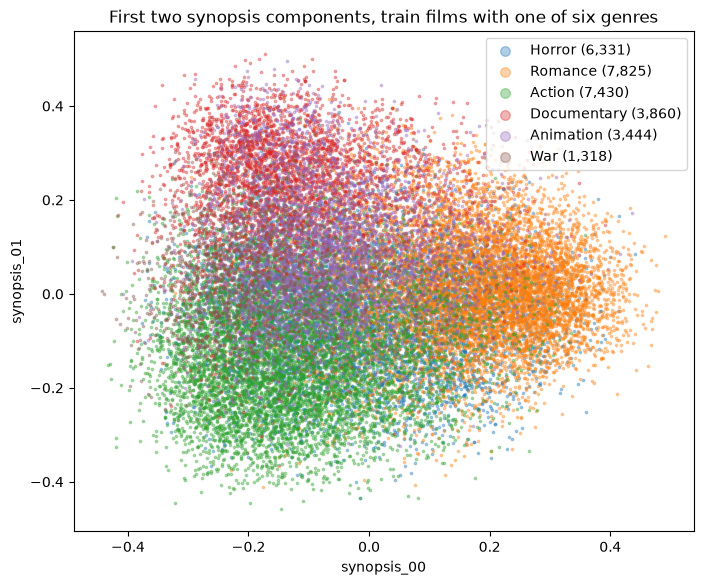

,synopsis_00,synopsis_01,synopsis_02
action,-0.13,-0.12,-0.04
animation,-0.07,0.09,-0.08
documentary,-0.12,0.22,0.08
horror,-0.01,-0.04,0.08
romance,0.17,0.01,-0.01
war,-0.16,0.03,-0.06


In [12]:
genres = ["Horror", "Romance", "Action", "Documentary", "Animation", "War"]
cols = [f"genre_{g.lower()}" for g in genres]
tr_s = tr[tr["has_synopsis"] == 1]
single = tr_s[tr_s[cols].sum(axis=1) == 1]  # films with exactly one of these genres
fig, ax = plt.subplots(figsize=(8, 6.5))
for g, c in zip(genres, cols):
    pts = single[single[c] == 1]
    ax.scatter(pts["synopsis_00"], pts["synopsis_01"], s=3, alpha=0.35, label=f"{g} ({len(pts):,})")
ax.set(xlabel="synopsis_00", ylabel="synopsis_01", title="First two synopsis components, train films with one of six genres")
ax.legend(markerscale=4)
plt.show()

means = single.groupby(single[cols].idxmax(axis=1).str.removeprefix("genre_"))[["synopsis_00", "synopsis_01", "synopsis_02"]].mean().round(2)
means

In [13]:
pca = json.loads((ROOT / "ml" / "artifacts" / "synopsis_pca.json").read_text(encoding="utf-8"))
print(pca["about"])
print("explained variance per component:", [round(x, 3) for x in pca["explained_variance_ratio"]])

PCA of MiniLM overview embeddings (revision 1110a243), fitted on 66,390 train films (<=2015); 16 components explain 28.5% of the variance.
explained variance per component: [0.035, 0.029, 0.023, 0.022, 0.021, 0.018, 0.017, 0.017, 0.015, 0.015, 0.014, 0.013, 0.012, 0.012, 0.011, 0.011]


## Findings

_From the `features` table in `data/movies.db`, built 2026-10-21: 79,199 films × 169 features._

**1. The table is complete.**
- Every film has a row.
- The revenue and score models may use all 169 features. The budget model may use 168, because `log_budget` is its own target.

**2. Missing values are where we expect them.**
- `log_budget` is missing for 83% of train films, because most films have no budget. Day 6 fills it in with the predicted budget.
- `franchise_revenue` is empty except for sequels (2–5% of films).
- Track-record revenue and score are missing for only 0.9%: the earliest 1960 films, which have no history yet.
- 48.3% of films have at least one theme, 98.9% have a synopsis, and 70.5% are "unrated/unknown".

**3. The strongest single signals, train only (Spearman).**

| Log revenue (8,050 films) | | Score (22,016 films) | |
| --- | --- | --- | --- |
| `franchise_revenue`* | +0.81 | `actors_score_mean` | +0.41 |
| `log_budget` | +0.68 | `actors_score_min` | +0.40 |
| `major_studio` | +0.41 | `director_score` | +0.38 |
| `actors_revenue_max` | +0.40 | `genre_horror` | −0.30 |
| `director_revenue` | +0.37 | `runtime` | +0.25 |
| `cert_unrated_unknown` | −0.32 | `genre_drama` | +0.24 |
| `country_US` | +0.31 | `language_en` | −0.22 |

\*`franchise_revenue` is measured only on the 730 sequels that have it, so it isn't comparable with the other rows.

The track-record features are among the strongest for both models, so using earlier films only still leaves real signal.

**4. Themes separate results.**
- **Revenue** (median train revenue across all revenue films: $36.8M):
  - **Highest:** superhero $259M, sequel or remake $117M, spy and conspiracy $88M.
  - **Lowest:** coming of age $37M, sex and erotica $31M, LGBTQ+ $12M.
- **Score:** true story has the highest average (6.80) and monsters and gore the lowest (5.76).
- **Comedy and satire was cleaned after the first run.** "amused", "absurd" and "campy" were dropped, because 40–51% of their films weren't comedies. Now 91% of the theme's 1,647 train films are tagged Comedy.
- **Some keyword noise remains**, from TMDB's tagging habits. "rape" puts *The Revenant* in sex and erotica, and "hilarious" puts a few action films in comedy and satire.

**5. Experience matters, but not in a straight line.**

| Director's earlier films | new | 1–2 | 3–5 | 6–10 | 11+ |
| --- | --- | --- | --- | --- | --- |
| Median revenue | $13.7M | $34.5M | $53.8M | $58.1M | $42.9M |
| Mean score | 6.19 | 6.28 | 6.34 | 6.40 | 6.34 |

- The test split has more new directors (38%) than train (31%).

**6. `covid_period` is always 0 in train.**
- COVID years only appear in the test split, so the model can't learn anything from this column. That is also why the notebook shows a "constant input" warning.
- Day 4 already plans to report test results with and without 2020–21.

**7. The synopsis numbers carry story type.**
- On the first component, romance (+0.17) sits opposite war (−0.16) and action (−0.13).
- Documentary stands out on the second (+0.22).
- The 16 numbers keep 28.5% of the variance.

**Verdict.** The feature table is ready for Day 4: complete, leak-tested, and carrying real signal for both revenue and score.